In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

In [25]:
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow.keras.layers import Dense
from tensorflow.keras.models import Sequential
from tensorflow import keras
import os
import shutil
import random
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

classes = ['Healthy Rice Leaf', 'Brown Spot', 'Leaf Blast', 'Bacterial Leaf Blight']
CLASS_SIZE = len(classes)
input_dir = Path("/kaggle/input/rice-disease-dataset/Rice_Leaf_AUG")
output_dir = Path("output")


In [4]:
def prepare_data():
    
    train_ratio = 0.7
    val_ratio = 0.15
    test_ratio = 0.15
    
    for split in ["train", "val", "test"]:
        for c in classes:
            (output_dir / split / c).mkdir(parents=True, exist_ok=True)
    
    for c in classes:
        images = list((input_dir / c).glob("*.*"))
        random.shuffle(images)
    
        n_total = len(images)
        n_train = int(train_ratio * n_total)
        n_val = int(val_ratio * n_total)
    
        train_images = images[:n_train]
        val_images = images[n_train:n_train + n_val]
        test_images = images[n_train + n_val:]
    
        for img in train_images:
            shutil.copy(img, output_dir / "train" / c / img.name)
        for img in val_images:
            shutil.copy(img, output_dir / "val" / c / img.name)
        for img in test_images:
            shutil.copy(img, output_dir / "test" / c / img.name)


prepare_data()

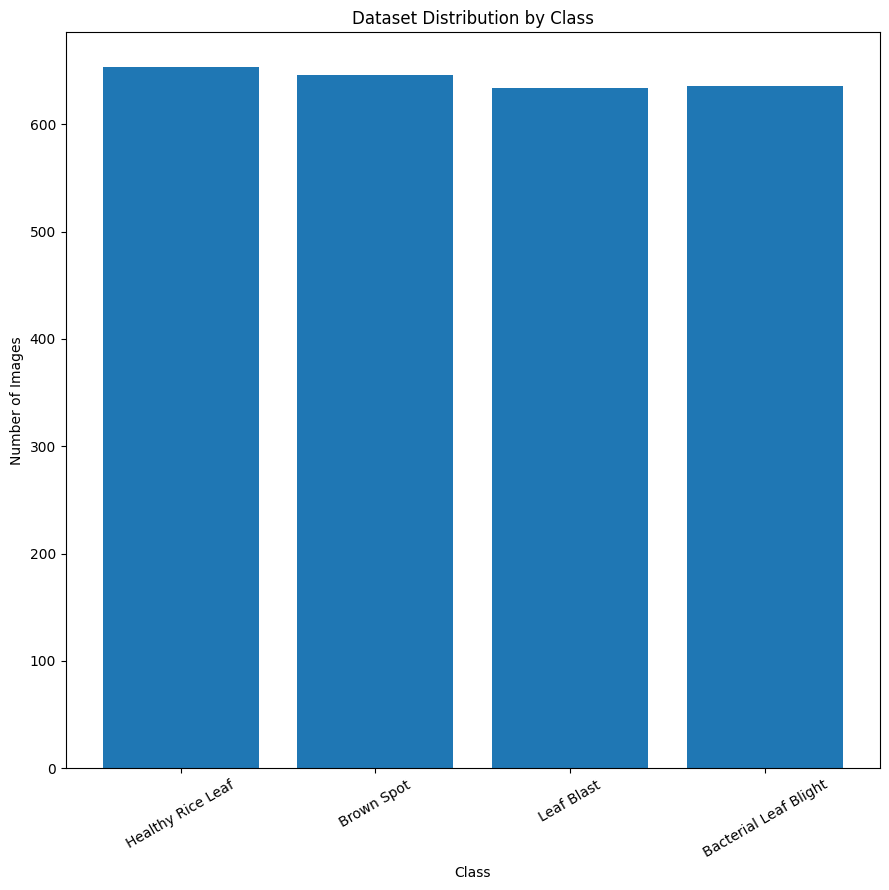

In [200]:
def plot_bar_chart():
    counts = []
    types = ['train', 'val', 'test']
    for i, c in enumerate(classes):
            images = list((input_dir / c).glob("*.*"))
            counts.append(len(images))
    plt.figure(figsize=(9, 9))
    plt.bar(classes, counts)
    plt.xlabel('Class')
    plt.ylabel('Number of Images')
    plt.title('Dataset Distribution by Class')
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()
    
plot_bar_chart()

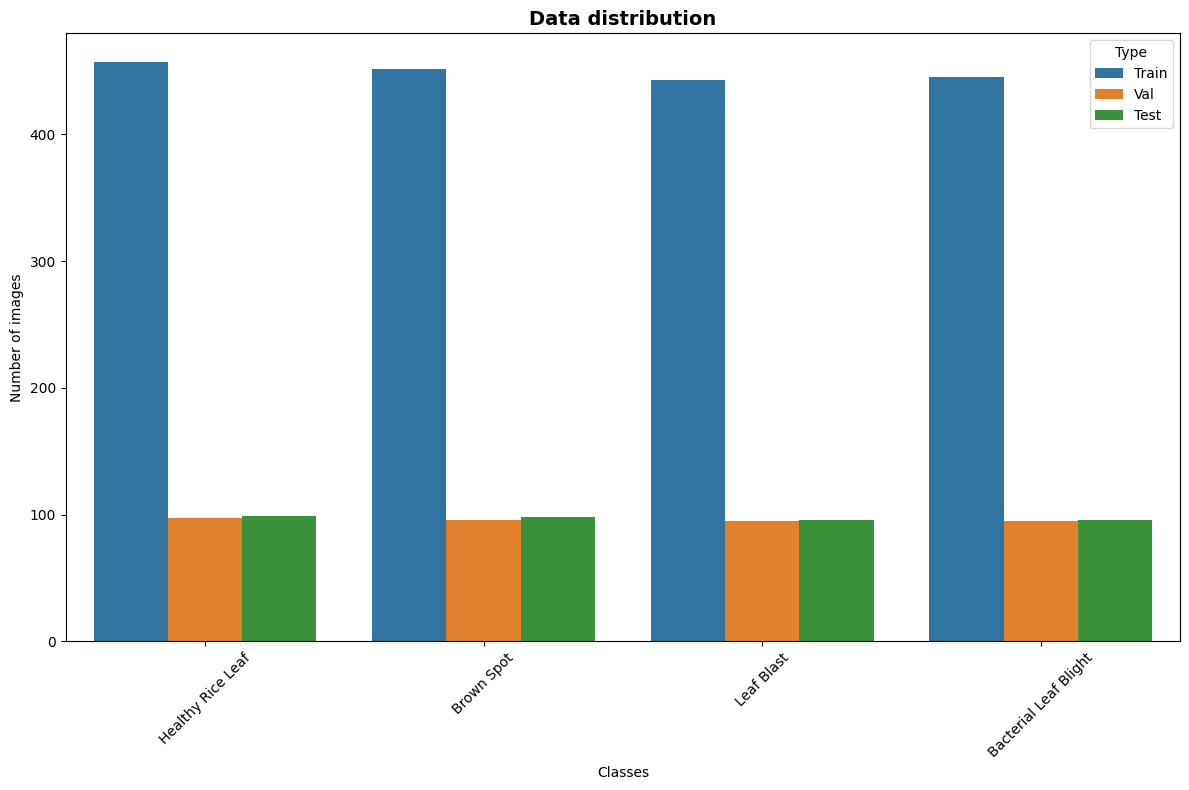

Split                  Test  Train  Val
Class                                  
Bacterial Leaf Blight    96    445   95
Brown Spot               98    452   96
Healthy Rice Leaf        99    457   97
Leaf Blast               96    443   95


In [201]:
def plot_dataset_distribution():
    
    data = []
    types = ['train', 'val', 'test']
    
    for t in types:
        for c in classes:
            class_path = output_dir / t / c
            count = len(list(class_path.glob("*.*")))
            data.append({'Class': c, 'Split': t.capitalize(), 'Count': count})
    
    df = pd.DataFrame(data)
    
    plt.figure(figsize=(12, 8))
    sns.barplot(data=df, x='Class', y='Count', hue='Split')
    
    plt.title('Data distribution', fontsize=14, fontweight='bold')
    plt.xlabel('Classes')
    plt.ylabel('Number of images')
    plt.xticks(rotation=45)
    plt.legend(title='Type')
    plt.tight_layout()
    plt.show()
    
    print(df.pivot_table(values='Count', index='Class', columns='Split', aggfunc='sum'))

plot_dataset_distribution()

In [158]:
# import cv2
# import albumentations as A

# class DataAugmentationAlb:
#     def __init__(self, path="output/train"):
#         self.path = Path(path)

#         self.flip_h = A.HorizontalFlip(p=0.5)
#         self.flip_v = A.VerticalFlip(p=0.5)
#         self.rotate = A.Rotate(limit=(-30, 30), p=0.5, border_mode=cv2.BORDER_REFLECT)
#         self.scale = A.ShiftScaleRotate(shift_limit=0.1, scale_limit=0.1, rotate_limit=0, p=0.5)

#     def read_images(self, class_path):
#         images = list(Path(class_path).glob("*.*"))
#         random.shuffle(images)
#         return images
        

#     def save_augmented(self, img, orig_path, suffix, class_name):

#         out_dir = self.path / class_name
#         orig_name = Path(orig_path).stem
#         ext = Path(orig_path).suffix
#         new_name = f"{suffix}_{orig_name}{ext}"
#         save_path = out_dir / new_name
#         cv2.imwrite(str(save_path), img)
                
#     def apply_one_transform(self, transform, suffix):

#         for class_name in classes:
#             class_dir = self.path / class_name
#             images_paths = self.read_images(class_dir)
            
#             for p in images_paths:
#                 if Path(p).stem.startswith(('flipH', 'flipV', 'rotate', 'scale')):
#                     continue
                
#                 img = cv2.imread(str(p))
#                 if img is None:
#                     continue
                
#                 aug = transform(image=img)["image"]
#                 self.save_augmented(aug, p, suffix, class_name)

#     def augment(self):
#         self.apply_one_transform(self.flip_h, "flipH")
#         self.apply_one_transform(self.flip_v, "flipV")
#         self.apply_one_transform(self.rotate, "rotate")
#         self.apply_one_transform(self.scale, "scale")

# aug = DataAugmentationAlb()
# aug.augment()


/usr/local/lib/python3.11/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)


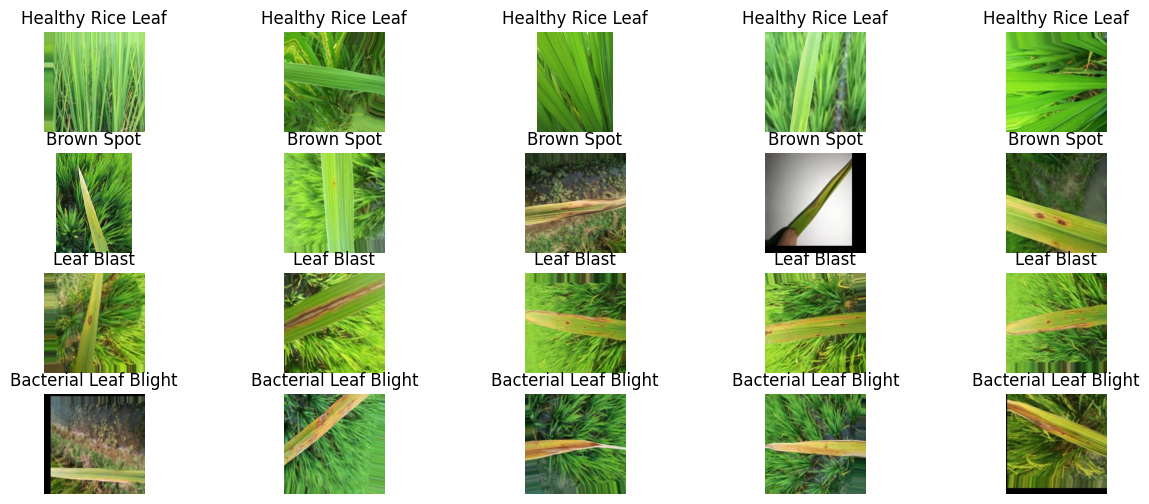

In [159]:
import matplotlib.pyplot as plt
def plot_some_images():
    fig = plt.figure(figsize=(15, 6))
    for i, c in enumerate(classes):
        images = list((output_dir / 'train' / c).glob("*.*"))
        samples = random.sample(images, 5)
        samples = map(cv2.imread, samples)
        samples = list(map(lambda image: cv2.cvtColor(image, cv2.COLOR_BGR2RGB), samples))
        for j  in range(5):
            plt.subplot(4, 5, i*5 + j+1)
            plt.imshow(samples[j])  
            plt.axis('off')
            plt.title(c) 
        
    plt.show()

plot_some_images()

# AlexNet

In [202]:
def create_alexnet_datasets():
    def load_image(path, label):
        img = tf.io.read_file(path)
        img = tf.image.decode_jpeg(img, channels=3)
        img = tf.image.resize(img, (224, 224))
        img = tf.cast(img, tf.float32) / 255.0
        return img, label
    
    train_paths, train_labels = [], []
    test_paths, test_labels = [], []
    val_paths, val_labels = [], []
    
    label_map = {c: i for i, c in enumerate(classes)}
    
    for c in classes:
        class_id = label_map[c]
    
        for p in (output_dir / "train" / c).glob("*.*"):
            train_paths.append(str(p))
            train_labels.append(class_id)
    
        for p in (output_dir / "test" / c).glob("*.*"):
            test_paths.append(str(p))
            test_labels.append(class_id)

        for p in (output_dir / "val" / c).glob("*.*"):
            val_paths.append(str(p))
            val_labels.append(class_id)
            
    train_ds = tf.data.Dataset.from_tensor_slices((train_paths, train_labels))
    test_ds  = tf.data.Dataset.from_tensor_slices((test_paths, test_labels))
    val_ds = tf.data.Dataset.from_tensor_slices((val_paths, val_labels))
    
    train_ds = train_ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    test_ds  = test_ds.map(load_image,  num_parallel_calls=tf.data.AUTOTUNE)
    val_ds  = val_ds.map(load_image,  num_parallel_calls=tf.data.AUTOTUNE)

    data_augmentation = keras.Sequential([
        keras.layers.RandomFlip(),
        keras.layers.RandomRotation(0.1),
        keras.layers.RandomZoom(0.1)
    ])
    train_ds = train_ds.map(lambda x, y: (data_augmentation(x), y))
    
    batch_size = 32
    train_ds = train_ds.shuffle(500).batch(batch_size).prefetch(tf.data.AUTOTUNE)
    test_ds  = test_ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)
    val_ds  = val_ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)
    return train_ds, test_ds, val_ds

train_ds, test_ds, val_ds = create_alexnet_datasets()

In [209]:
LEARNING_RATES = [0.01, 0.001, 0.0001]
def alexnet(lr=0.001):
    alexnet_model = keras.models.Sequential([
        keras.layers.Input(shape=(224, 224, 3)),
        
        keras.layers.Conv2D(filters=96, kernel_size=(11,11), strides=(4,4), padding='valid', activation='relu'),
        keras.layers.BatchNormalization(),
        keras.layers.MaxPool2D(pool_size=(3,3), strides=(2,2)),
    
        keras.layers.Conv2D(filters=256, kernel_size=(5,5), padding="same", activation='relu'),
        keras.layers.BatchNormalization(),
        keras.layers.MaxPool2D(pool_size=(3,3), strides=(2,2)),
    
        keras.layers.Conv2D(filters=384, kernel_size=(3,3), padding="same", activation='relu'),
        keras.layers.Conv2D(filters=384, kernel_size=(3,3), padding="same", activation='relu'),
        keras.layers.Conv2D(filters=256, kernel_size=(3,3), padding="same", activation='relu'),
        keras.layers.MaxPool2D(pool_size=(3,3), strides=(2,2)),
    
        keras.layers.Flatten(),
        keras.layers.Dense(4096, activation='relu'),
        keras.layers.Dropout(0.5),
    
        keras.layers.Dense(4096, activation='relu'),
        keras.layers.Dropout(0.5),
    
        keras.layers.Dense(CLASS_SIZE, activation='softmax')
    ])

    alexnet_model.compile(
        loss='sparse_categorical_crossentropy',
        optimizer=keras.optimizers.SGD(learning_rate=lr, momentum=0.9),
        metrics=['accuracy']    
    )
    return alexnet_model

alexnet_models = {}
for i in LEARNING_RATES:
    alexnet_models[i] = alexnet(i)
alexnet_models[i].summary()

Model: "sequential_49"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_251 (Conv2D)             │ (None, 54, 54, 96)     │        34,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_55          │ (None, 54, 54, 96)     │           384 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_114               │ (None, 26, 26, 96)     │             0 │
│ (MaxPooling2D)                  │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_252 (Conv2D)             │ (None, 26, 26, 256)    │       614,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_56          │ (None, 26, 26, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_115               │ (None, 12, 12, 256)    │             0 │
│ (MaxPooling2D)                  │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_253 (Conv2D)             │ (None, 12, 12, 384)    │       885,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_254 (Conv2D)             │ (None, 12, 12, 384)    │     1,327,488 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_255 (Conv2D)             │ (None, 12, 12, 256)    │       884,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_116               │ (None, 5, 5, 256)      │             0 │
│ (MaxPooling2D)                  │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_38 (Flatten)            │ (None, 6400)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_114 (Dense)               │ (None, 4096)           │    26,218,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_76 (Dropout)            │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_115 (Dense)               │ (None, 4096)           │    16,781,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_77 (Dropout)            │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_116 (Dense)               │ (None, 4)              │        16,388 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 46,764,804 (178.39 MB)

 Trainable params: 46,764,100 (178.39 MB)

 Non-trainable params: 704 (2.75 KB)

In [5]:
from sklearn.metrics import classification_report, confusion_matrix
def report_model(model, test_ds, history):

    y_true = []
    y_pred = []
    
    for images, labels in test_ds:
        predictions = model.predict(images, verbose=0)
        y_pred.extend(np.argmax(predictions, axis=1))
        y_true.extend(labels.numpy())
    
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)

    accuracy = np.mean(y_true == y_pred)
    report = classification_report(y_true, y_pred, target_names=classes, output_dict=True)

    print(f"Accuracy : {accuracy:.4f}")
    print(classification_report(y_true, y_pred, target_names=classes))

    plt.figure(figsize=(10, 8))
    cm = confusion_matrix(y_true, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                xticklabels=classes, yticklabels=classes)
    plt.title('Confusion Matrix')
    plt.ylabel('True Label')
    plt.xlabel('Predicted Label')
    plt.xticks(rotation=45)
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()
    
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
    ax1.plot(history.history['loss'], label='Train Loss')
    ax1.plot(history.history['val_loss'], label='Validation Loss')
    ax1.set_title('Model Loss')
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Loss')
    ax1.legend()
    
    ax2.plot(history.history['accuracy'], label='Train Accuracy')
    ax2.plot(history.history['val_accuracy'], label='Validation Accuracy')
    ax2.set_title('Model Accuracy')
    ax2.set_xlabel('Epoch')
    ax2.set_ylabel('Accuracy')
    ax2.legend()
    
    plt.tight_layout()
    plt.show()

    return {
        'accuracy': accuracy,
        'classification_report': report,
        'confusion_matrix': cm
    }



In [211]:
history_alexnet = {}
history_alexnet[0.0001] = alexnet_models[0.0001].fit(
    train_ds,
    epochs=20,
    validation_data=val_ds
)

Epoch 1/20
57/57 ━━━━━━━━━━━━━━━━━━━━ 32s 363ms/step - accuracy: 0.4424 - loss: 1.5012 - val_accuracy: 0.2480 - val_loss: 1.3838
Epoch 2/20
57/57 ━━━━━━━━━━━━━━━━━━━━ 25s 315ms/step - accuracy: 0.2070 - loss: 1.7476 - val_accuracy: 0.3368 - val_loss: 1.3801
Epoch 3/20
57/57 ━━━━━━━━━━━━━━━━━━━━ 25s 311ms/step - accuracy: 0.2027 - loss: 1.5255 - val_accuracy: 0.4569 - val_loss: 1.3749
Epoch 4/20
57/57 ━━━━━━━━━━━━━━━━━━━━ 25s 312ms/step - accuracy: 0.2904 - loss: 1.4016 - val_accuracy: 0.4700 - val_loss: 1.3579
Epoch 5/20
57/57 ━━━━━━━━━━━━━━━━━━━━ 25s 313ms/step - accuracy: 0.3560 - loss: 1.3404 - val_accuracy: 0.4125 - val_loss: 1.3234
Epoch 6/20
57/57 ━━━━━━━━━━━━━━━━━━━━ 25s 311ms/step - accuracy: 0.3969 - loss: 1.3006 - val_accuracy: 0.4360 - val_loss: 1.2596
Epoch 7/20
57/57 ━━━━━━━━━━━━━━━━━━━━ 25s 312ms/step - accuracy: 0.4001 - loss: 1.3064 - val_accuracy: 0.5065 - val_loss: 1.1917
Epoch 8/20
57/57 ━━━━━━━━━━━━━━━━━━━━ 24s 311ms/step - accuracy: 0.4312 - loss: 1.2621 - val_accu

In [212]:
history2 = alexnet_models[0.0001].fit(
    train_ds,
    validation_data=val_ds,
    initial_epoch=20,
    epochs=30
)

Epoch 21/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 25s 312ms/step - accuracy: 0.5865 - loss: 0.9877 - val_accuracy: 0.6397 - val_loss: 0.8366
Epoch 22/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 25s 311ms/step - accuracy: 0.5536 - loss: 1.0663 - val_accuracy: 0.6188 - val_loss: 0.8703
Epoch 23/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 25s 311ms/step - accuracy: 0.5660 - loss: 1.0372 - val_accuracy: 0.6345 - val_loss: 0.8516
Epoch 24/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 24s 310ms/step - accuracy: 0.5951 - loss: 0.9809 - val_accuracy: 0.5979 - val_loss: 0.9014
Epoch 25/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 24s 309ms/step - accuracy: 0.5747 - loss: 1.0083 - val_accuracy: 0.6188 - val_loss: 0.8315
Epoch 26/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 25s 310ms/step - accuracy: 0.5817 - loss: 1.0275 - val_accuracy: 0.6188 - val_loss: 0.9088
Epoch 27/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 24s 310ms/step - accuracy: 0.5849 - loss: 0.9951 - val_accuracy: 0.6240 - val_loss: 0.8377
Epoch 28/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 24s 311ms/step - accuracy: 0.5849 - loss: 0.9990 - 

In [213]:
history3 = alexnet_models[0.0001].fit(
    train_ds,
    validation_data=val_ds,
    initial_epoch=30,
    epochs=40
)

Epoch 31/40
57/57 ━━━━━━━━━━━━━━━━━━━━ 25s 311ms/step - accuracy: 0.6198 - loss: 0.9070 - val_accuracy: 0.6449 - val_loss: 0.8171
Epoch 32/40
57/57 ━━━━━━━━━━━━━━━━━━━━ 25s 312ms/step - accuracy: 0.6218 - loss: 0.9084 - val_accuracy: 0.6292 - val_loss: 0.8159
Epoch 33/40
57/57 ━━━━━━━━━━━━━━━━━━━━ 25s 310ms/step - accuracy: 0.6436 - loss: 0.9113 - val_accuracy: 0.6841 - val_loss: 0.7770
Epoch 34/40
57/57 ━━━━━━━━━━━━━━━━━━━━ 25s 311ms/step - accuracy: 0.6298 - loss: 0.8756 - val_accuracy: 0.6580 - val_loss: 0.8891
Epoch 35/40
57/57 ━━━━━━━━━━━━━━━━━━━━ 25s 309ms/step - accuracy: 0.6829 - loss: 0.8316 - val_accuracy: 0.6971 - val_loss: 0.8079
Epoch 36/40
57/57 ━━━━━━━━━━━━━━━━━━━━ 25s 318ms/step - accuracy: 0.6463 - loss: 0.8692 - val_accuracy: 0.6997 - val_loss: 0.7679
Epoch 37/40
57/57 ━━━━━━━━━━━━━━━━━━━━ 25s 311ms/step - accuracy: 0.6445 - loss: 0.8838 - val_accuracy: 0.7023 - val_loss: 0.7688
Epoch 38/40
57/57 ━━━━━━━━━━━━━━━━━━━━ 25s 317ms/step - accuracy: 0.6791 - loss: 0.8121 - 

In [8]:
def merge_histories(*histories):
    merged = {}

    for hist in histories:
        for key, values in hist.history.items():
            if key not in merged:
                merged[key] = list(values)
            else:
                merged[key].extend(values)

    return type('MergedHistory', (), {"history": merged})

In [ ]:
history1 = history_alexnet[0.0001]
merged_history = merge_histories(history1, history2, history3)
results_alexnet = report_model(alexnet_models[0.0001], test_ds, merged_history)

In [215]:
history_alexnet[0.01] = alexnet_models[0.01].fit(
    train_ds,
    epochs=30,
    validation_data=val_ds
)

Epoch 1/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 32s 363ms/step - accuracy: 0.5443 - loss: 1.2996 - val_accuracy: 0.2480 - val_loss: 1.4803
Epoch 2/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 25s 310ms/step - accuracy: 0.0488 - loss: 1.6588 - val_accuracy: 0.2480 - val_loss: 1.3989
Epoch 3/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 24s 308ms/step - accuracy: 0.0493 - loss: 1.5070 - val_accuracy: 0.2480 - val_loss: 1.3993
Epoch 4/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 25s 310ms/step - accuracy: 0.0531 - loss: 1.5112 - val_accuracy: 0.2480 - val_loss: 1.3996
Epoch 5/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 25s 310ms/step - accuracy: 0.0595 - loss: 1.5068 - val_accuracy: 0.2480 - val_loss: 1.3988
Epoch 6/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 25s 311ms/step - accuracy: 0.0636 - loss: 1.5043 - val_accuracy: 0.2480 - val_loss: 1.3988
Epoch 7/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 25s 317ms/step - accuracy: 0.0556 - loss: 1.5098 - val_accuracy: 0.2480 - val_loss: 1.3996
Epoch 8/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 25s 309ms/step - accuracy: 0.0527 - loss: 1.5151 - val_accu

/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classif

Accuracy : 0.2468
                       precision    recall  f1-score   support

    Healthy Rice Leaf       0.00      0.00      0.00        99
           Brown Spot       0.00      0.00      0.00        98
           Leaf Blast       0.00      0.00      0.00        96
Bacterial Leaf Blight       0.25      1.00      0.40        96

             accuracy                           0.25       389
            macro avg       0.06      0.25      0.10       389
         weighted avg       0.06      0.25      0.10       389



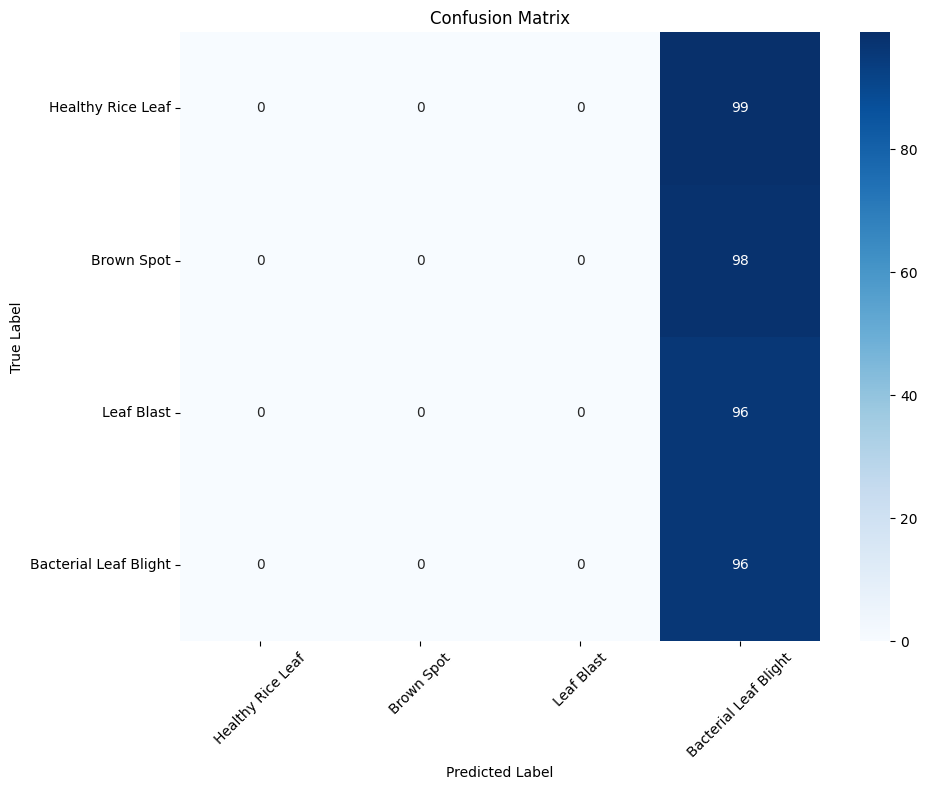

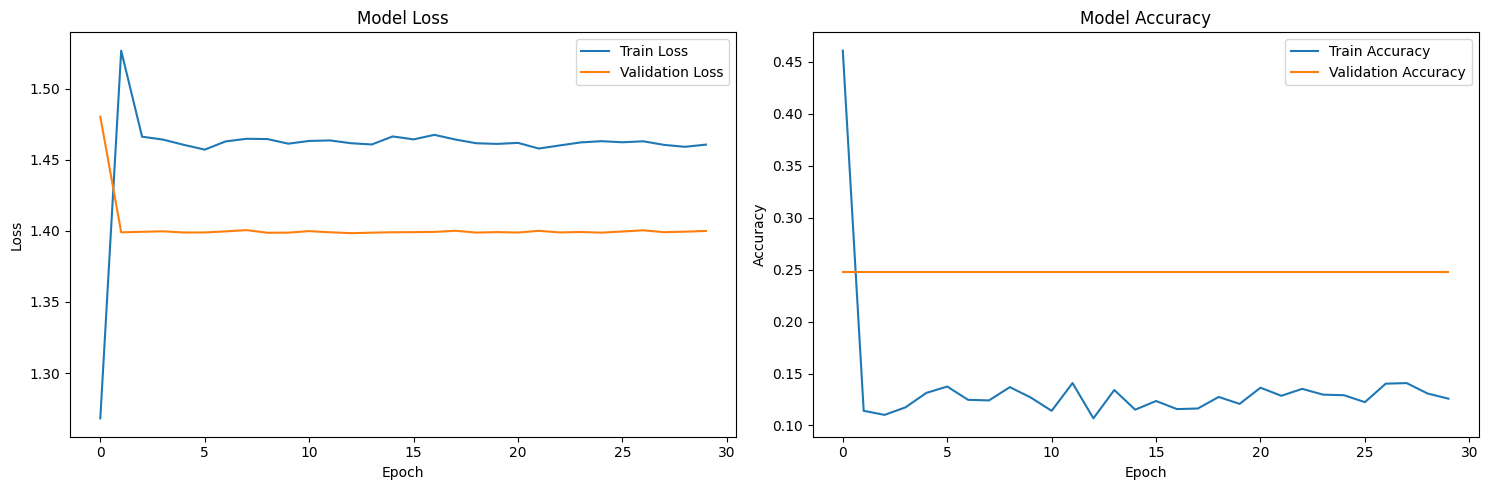

In [217]:
results_alexnet = report_model(alexnet_models[0.01], test_ds, history_alexnet[0.01])

In [214]:
history_alexnet[0.001] = alexnet_models[0.001].fit(
    train_ds,
    epochs=30,
    validation_data=val_ds
)

Epoch 1/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 32s 354ms/step - accuracy: 0.5631 - loss: 1.1794 - val_accuracy: 0.3185 - val_loss: 1.3761
Epoch 2/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 24s 309ms/step - accuracy: 0.3464 - loss: 1.4777 - val_accuracy: 0.2663 - val_loss: 1.3696
Epoch 3/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 24s 309ms/step - accuracy: 0.2809 - loss: 1.5362 - val_accuracy: 0.2533 - val_loss: 1.3652
Epoch 4/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 25s 312ms/step - accuracy: 0.2954 - loss: 1.5087 - val_accuracy: 0.4648 - val_loss: 1.2988
Epoch 5/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 24s 310ms/step - accuracy: 0.2628 - loss: 1.5272 - val_accuracy: 0.4204 - val_loss: 1.2914
Epoch 6/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 25s 311ms/step - accuracy: 0.2563 - loss: 1.3169 - val_accuracy: 0.3734 - val_loss: 1.4120
Epoch 7/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 25s 310ms/step - accuracy: 0.3462 - loss: 1.4648 - val_accuracy: 0.4674 - val_loss: 1.1782
Epoch 8/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 24s 310ms/step - accuracy: 0.3793 - loss: 1.2918 - val_accu

Accuracy : 0.6607
                       precision    recall  f1-score   support

    Healthy Rice Leaf       0.90      0.97      0.93        99
           Brown Spot       0.93      0.29      0.44        98
           Leaf Blast       0.58      0.43      0.49        96
Bacterial Leaf Blight       0.51      0.96      0.66        96

             accuracy                           0.66       389
            macro avg       0.73      0.66      0.63       389
         weighted avg       0.73      0.66      0.63       389



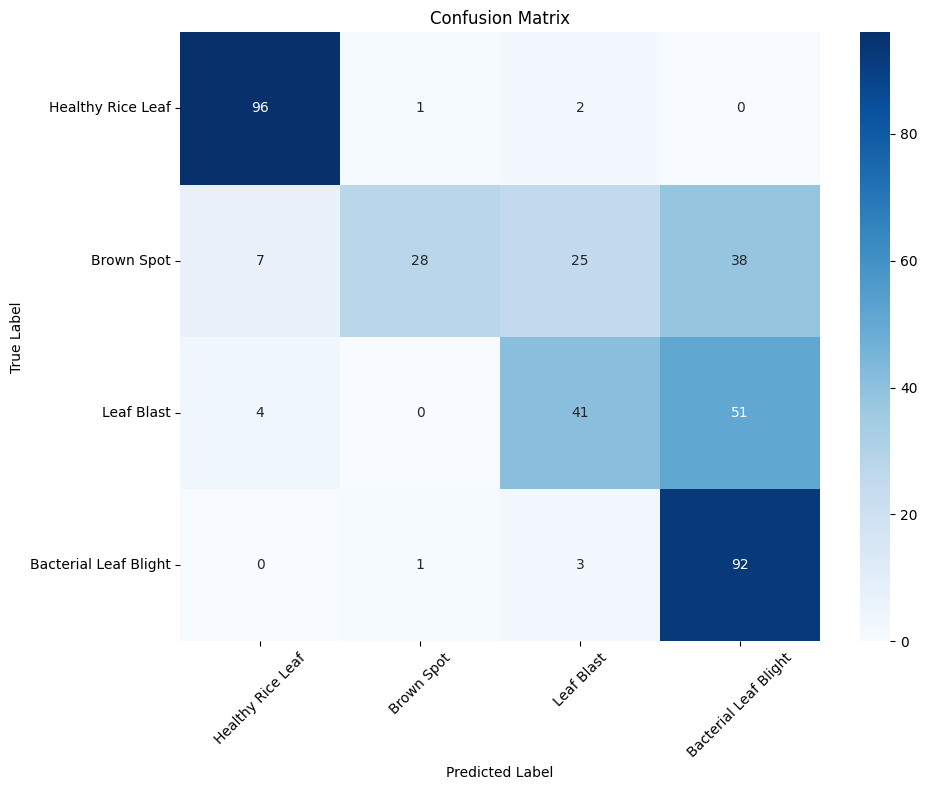

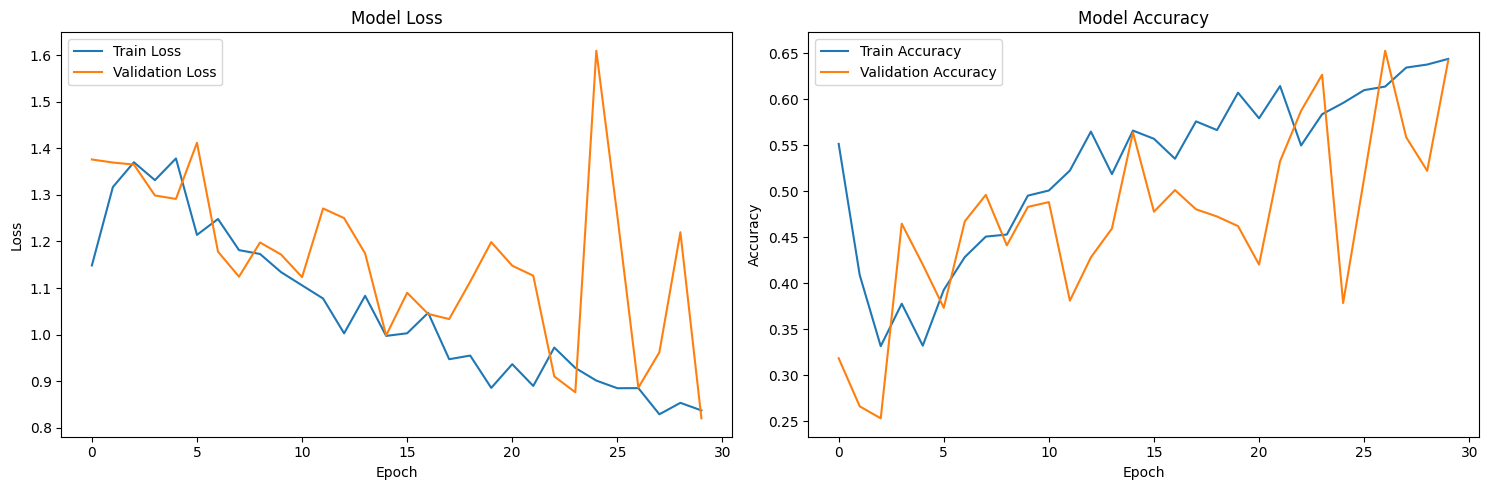

In [218]:
results_alexnet = report_model(alexnet_models[0.001], test_ds, history_alexnet[0.001])

In [24]:
def compute_metrics_from_dataset(model, test_ds):
    y_true = []
    y_pred = []

    for images, labels in test_ds:
        images_np = images.numpy() if tf.is_tensor(images) else images
        labels_np = labels.numpy() if tf.is_tensor(labels) else labels

        preds = model.predict(images_np, verbose=0)
        preds_class = np.argmax(preds, axis=1)

        y_true.extend(labels_np)
        y_pred.extend(preds_class)

    y_true = np.array(y_true)
    y_pred = np.array(y_pred)

    cm = confusion_matrix(y_true, y_pred)

    metrics = []
    for i, class_name in enumerate(classes):
        TP = cm[i, i]
        FN = cm[i, :].sum() - TP
        FP = cm[:, i].sum() - TP
        TN = cm.sum() - (TP + FP + FN)

        accuracy = (TP + TN) / cm.sum()
        sensitivity = TP / (TP + FN) if (TP + FN) > 0 else 0
        specificity = TN / (TN + FP) if (TN + FP) > 0 else 0

        metrics.append({
            "Class": class_name,
            "Accuracy": round(accuracy, 4),
            "Sensitivity": round(sensitivity, 4),
            "Specificity": round(specificity, 4)
        })

    metrics_df = pd.DataFrame(metrics)
    return metrics_df


In [ ]:
compute_metrics_from_dataset(alexnet_models[0.0001], test_ds)

# INC-VGG

In [19]:
from tensorflow.keras.applications import VGG19
IMAGE_SIZE = [ 224 , 224 , 3 ]
vgg = VGG19( include_top = False,
            input_shape = IMAGE_SIZE,
            weights = 'imagenet')

vgg.trainable = False

vgg = keras.Model(inputs=vgg.input, outputs=vgg.get_layer('block4_conv3').output)

class InceptionModule(keras.layers.Layer):
    def __init__(self, name=None):
        super().__init__(name=name)

        self.b1_1 = keras.layers.Conv2D(64, 1, padding="same")
        self.b1_bn = keras.layers.BatchNormalization()
        
        self.b2_1 = keras.layers.Conv2D(64, 1, padding="same")
        self.b2_1_bn = keras.layers.BatchNormalization()
        self.b2_2 = keras.layers.Conv2D(64, 3, padding="same")
        self.b2_2_bn = keras.layers.BatchNormalization()
        
        self.b3_1 = keras.layers.Conv2D(32, 1, padding="same")
        self.b3_1_bn = keras.layers.BatchNormalization()
        self.b3_2 = keras.layers.Conv2D(64, 3, padding="same")
        self.b3_2_bn = keras.layers.BatchNormalization()
        self.b3_3 = keras.layers.Conv2D(64, 3, padding="same")
        self.b3_3_bn = keras.layers.BatchNormalization()
        
        self.pool = keras.layers.AveragePooling2D(pool_size=3, strides=1, padding="same")
        self.b4_1 = keras.layers.Conv2D(64, 1, padding="same")
        self.b4_1_bn = keras.layers.BatchNormalization()
        
        self.concat = keras.layers.Concatenate()

    def call(self, x):
        b1 = self.b1_1(x)
        b1 = self.b1_bn(b1)
        b1 = tf.nn.swish(b1)

        
        b2 = self.b2_1(x)
        b2 = self.b2_1_bn(b2)
        b2 = tf.nn.swish(b2)
        b2 = self.b2_2(b2)
        b2 = self.b2_2_bn(b2)
        b2 = tf.nn.swish(b2)

        b3 = self.b3_1(x)
        b3 = self.b3_1_bn(b3)
        b3 = tf.nn.swish(b3)
        b3 = self.b3_2(b3)
        b3 = self.b3_2_bn(b3)
        b3 = tf.nn.swish(b3)
        b3 = self.b3_3(b3)
        b3 = self.b3_3_bn(b3)
        b3 = tf.nn.swish(b3)
        
        b4 = self.pool(x)
        b4 = self.b4_1(b4)
        b4 = self.b4_1_bn(b4)
        b4 = tf.nn.swish(b4)

        return self.concat([b1, b2, b3, b4])


paper_model = keras.models.Sequential([
    keras.layers.Input(shape=IMAGE_SIZE),
    vgg,
    keras.layers.MaxPooling2D(2, 2, name='Pool3'),
    keras.layers.Conv2D(512, 3, padding='same'),
    keras.layers.BatchNormalization(),
    keras.layers.Activation("swish"),

    InceptionModule(name="Inception_1"),
    InceptionModule(name="Inception_2"),
    
    keras.layers.GlobalAveragePooling2D(name='Pool4'),
    keras.layers.Dense(CLASS_SIZE, activation='softmax', name='predictions')
])

paper_model.compile(
    loss='sparse_categorical_crossentropy',
    optimizer=tf.optimizers.Adam(learning_rate=0.001),
    metrics=['accuracy']
)
paper_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ functional_3 (Functional)       │ (None, 28, 28, 512)    │     8,225,344 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Pool3 (MaxPooling2D)            │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_15          │ (None, 14, 14, 512)    │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Inception_1 (InceptionModule)   │ (None, 14, 14, 256)    │       208,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Inception_2 (InceptionModule)   │ (None, 14, 14, 256)    │       151,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Pool4 (GlobalAveragePooling2D)  │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,948,740 (41.77 MB)

 Trainable params: 2,720,708 (10.38 MB)

 Non-trainable params: 8,228,032 (31.39 MB)

In [20]:
def create_vgg_datasets():
    
    IMAGENET_MEAN = tf.constant([0.485, 0.456, 0.406])
    IMAGENET_STD  = tf.constant([0.229, 0.224, 0.225])
    
    def normalize_image(image, label):
        image = tf.cast(image, tf.float32) / 255.0
        image = (image - IMAGENET_MEAN) / IMAGENET_STD
        return image, label

    def load_image(path, label):
        img = tf.io.read_file(path)
        img = tf.image.decode_jpeg(img, channels=3)
        img = tf.image.resize(img, (224, 224))
        return img, label
    
    train_paths, train_labels = [], []
    test_paths, test_labels = [], []
    val_paths, val_labels = [], []
    
    label_map = {c: i for i, c in enumerate(classes)}
    
    for c in classes:
        class_id = label_map[c]
    
        for p in (output_dir / "train" / c).glob("*.*"):
            train_paths.append(str(p))
            train_labels.append(class_id)
    
        for p in (output_dir / "test" / c).glob("*.*"):
            test_paths.append(str(p))
            test_labels.append(class_id)

        for p in (output_dir / "val" / c).glob("*.*"):
            val_paths.append(str(p))
            val_labels.append(class_id)

    
    train_ds = tf.data.Dataset.from_tensor_slices((train_paths, train_labels))
    test_ds  = tf.data.Dataset.from_tensor_slices((test_paths, test_labels))
    val_ds = tf.data.Dataset.from_tensor_slices((val_paths, val_labels))
    
    
    train_ds = train_ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    test_ds  = test_ds.map(load_image,  num_parallel_calls=tf.data.AUTOTUNE)
    val_ds  = val_ds.map(load_image,  num_parallel_calls=tf.data.AUTOTUNE)
    
    data_augmentation = keras.Sequential([
        keras.layers.RandomFlip(),
        keras.layers.RandomRotation(0.1),
        keras.layers.RandomZoom(0.1)
    ])
    train_ds = train_ds.map(lambda x, y: (data_augmentation(x), y))

    train_ds = train_ds.map(normalize_image, num_parallel_calls=tf.data.AUTOTUNE)
    val_ds = val_ds.map(normalize_image, num_parallel_calls=tf.data.AUTOTUNE)
    test_ds = test_ds.map(normalize_image, num_parallel_calls=tf.data.AUTOTUNE)

    
    
    batch_size = 64
    
    train_ds = train_ds.shuffle(500).batch(batch_size).prefetch(tf.data.AUTOTUNE)
    test_ds  = test_ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)
    val_ds  = val_ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)
    return train_ds, test_ds, val_ds

paper_train_ds, paper_test_ds, paper_val_ds = create_vgg_datasets()

In [21]:
paper_history = {}
paper_history[10] = paper_model.fit(
    paper_train_ds,
    epochs=20,
    validation_data=paper_val_ds
)

Epoch 1/20


2025-12-01 01:01:57.938241: E external/local_xla/xla/service/slow_operation_alarm.cc:65] Trying algorithm eng36{k2=3,k3=0} for conv (f32[64,64,224,224]{3,2,1,0}, u8[0]{0}) custom-call(f32[64,64,224,224]{3,2,1,0}, f32[64,64,3,3]{3,2,1,0}, f32[64]{0}), window={size=3x3 pad=1_1x1_1}, dim_labels=bf01_oi01->bf01, custom_call_target="__cudnn$convBiasActivationForward", backend_config={"cudnn_conv_backend_config":{"activation_mode":"kRelu","conv_result_scale":1,"leakyrelu_alpha":0,"side_input_scale":0},"force_earliest_schedule":false,"operation_queue_id":"0","wait_on_operation_queues":[]} is taking a while...
2025-12-01 01:01:58.189428: E external/local_xla/xla/service/slow_operation_alarm.cc:133] The operation took 1.251293738s
Trying algorithm eng36{k2=3,k3=0} for conv (f32[64,64,224,224]{3,2,1,0}, u8[0]{0}) custom-call(f32[64,64,224,224]{3,2,1,0}, f32[64,64,3,3]{3,2,1,0}, f32[64]{0}), window={size=3x3 pad=1_1x1_1}, dim_labels=bf01_oi01->bf01, custom_call_target="__cudnn$convBiasActivationF

29/29 ━━━━━━━━━━━━━━━━━━━━ 107s 2s/step - accuracy: 0.6343 - loss: 1.0683 - val_accuracy: 0.2507 - val_loss: 33.4397
Epoch 2/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 36s 981ms/step - accuracy: 0.4575 - loss: 1.4218 - val_accuracy: 0.3420 - val_loss: 3.7963
Epoch 3/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 37s 1s/step - accuracy: 0.4791 - loss: 1.1661 - val_accuracy: 0.2950 - val_loss: 8.8117
Epoch 4/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 36s 995ms/step - accuracy: 0.4983 - loss: 1.1631 - val_accuracy: 0.4204 - val_loss: 3.4966
Epoch 5/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 36s 983ms/step - accuracy: 0.5424 - loss: 1.0632 - val_accuracy: 0.5901 - val_loss: 1.5554
Epoch 6/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 37s 1s/step - accuracy: 0.6156 - loss: 0.9653 - val_accuracy: 0.6240 - val_loss: 1.5001
Epoch 7/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 36s 983ms/step - accuracy: 0.6500 - loss: 0.8659 - val_accuracy: 0.5326 - val_loss: 1.3213
Epoch 8/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 36s 995ms/step - accuracy: 0.6777 - loss: 0.8068 - val_accuracy: 0.6162 - val

In [22]:
paper_history[20] = paper_model.fit(
    paper_train_ds,
    initial_epoch=20,
    epochs=40,
    validation_data=paper_val_ds
)

Epoch 21/40
29/29 ━━━━━━━━━━━━━━━━━━━━ 36s 988ms/step - accuracy: 0.8185 - loss: 0.5125 - val_accuracy: 0.8146 - val_loss: 0.5077
Epoch 22/40
29/29 ━━━━━━━━━━━━━━━━━━━━ 36s 990ms/step - accuracy: 0.8890 - loss: 0.3498 - val_accuracy: 0.9034 - val_loss: 0.2734
Epoch 23/40
29/29 ━━━━━━━━━━━━━━━━━━━━ 36s 983ms/step - accuracy: 0.9013 - loss: 0.3325 - val_accuracy: 0.9086 - val_loss: 0.2569
Epoch 24/40
29/29 ━━━━━━━━━━━━━━━━━━━━ 36s 983ms/step - accuracy: 0.8676 - loss: 0.3860 - val_accuracy: 0.8251 - val_loss: 0.5136
Epoch 25/40
29/29 ━━━━━━━━━━━━━━━━━━━━ 36s 994ms/step - accuracy: 0.8551 - loss: 0.4289 - val_accuracy: 0.6423 - val_loss: 1.3421
Epoch 26/40
29/29 ━━━━━━━━━━━━━━━━━━━━ 36s 973ms/step - accuracy: 0.8531 - loss: 0.4532 - val_accuracy: 0.7833 - val_loss: 0.6061
Epoch 27/40
29/29 ━━━━━━━━━━━━━━━━━━━━ 36s 988ms/step - accuracy: 0.8420 - loss: 0.4978 - val_accuracy: 0.8146 - val_loss: 0.4687
Epoch 28/40
29/29 ━━━━━━━━━━━━━━━━━━━━ 37s 997ms/step - accuracy: 0.8954 - loss: 0.3196 - 

In [27]:
paper_history = merge_histories(paper_history[10], paper_history[20])

Accuracy : 0.8612
                       precision    recall  f1-score   support

    Healthy Rice Leaf       0.90      1.00      0.95        99
           Brown Spot       0.94      0.64      0.76        98
           Leaf Blast       0.84      0.84      0.84        96
Bacterial Leaf Blight       0.80      0.96      0.87        96

             accuracy                           0.86       389
            macro avg       0.87      0.86      0.86       389
         weighted avg       0.87      0.86      0.86       389



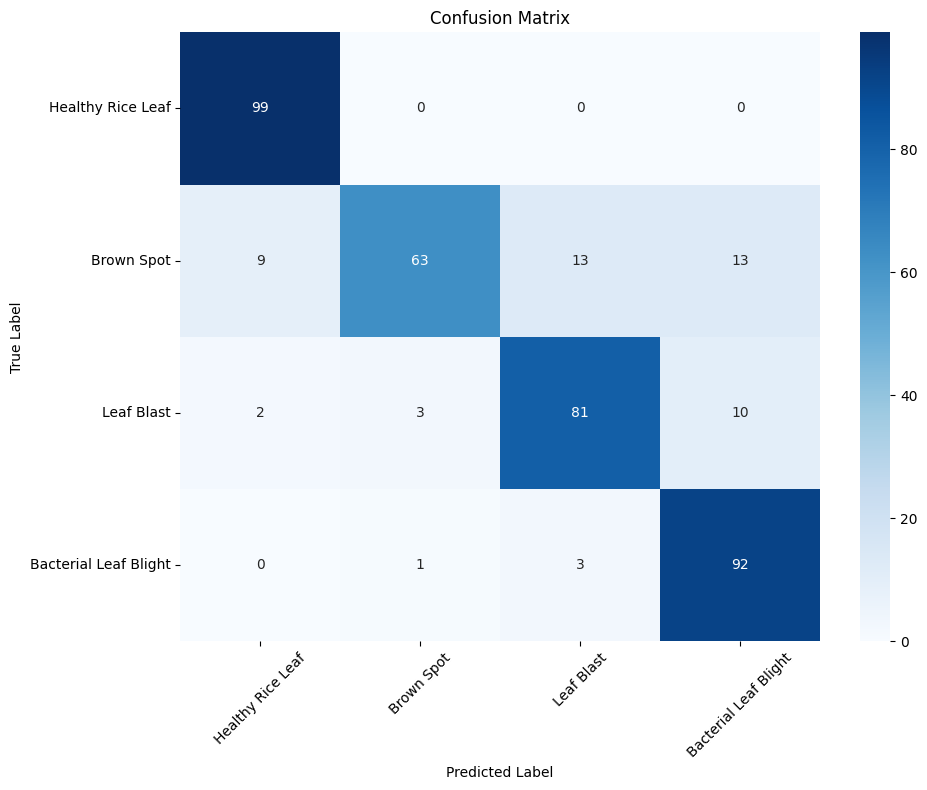

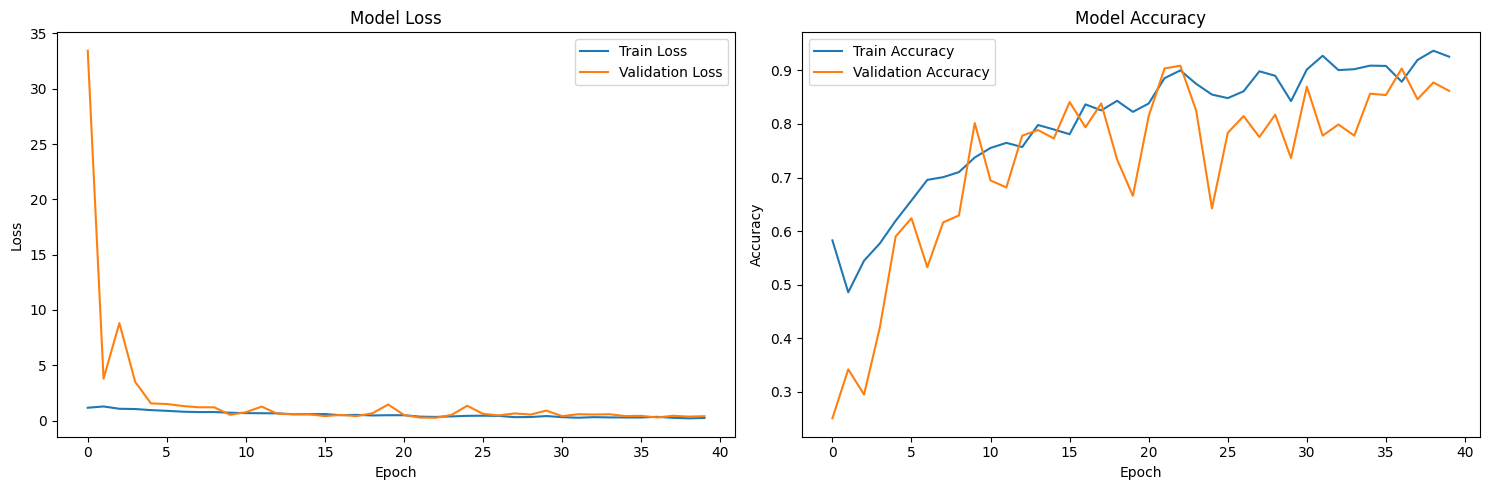

In [28]:
results_paper = report_model(paper_model, paper_test_ds, paper_history)

In [29]:
compute_metrics_from_dataset(paper_model, paper_test_ds)

,Class,Accuracy,Sensitivity,Specificity
0,Healthy Rice Leaf,0.9717,1.0000,0.9621
1,Brown Spot,0.8997,0.6429,0.9863
2,Leaf Blast,0.9203,0.8438,0.9454
3,Bacterial Leaf Blight,0.9306,0.9583,0.9215
